# 📩 Analisis Kata Kunci SMS Spam vs Ham dengan TF-IDF

**Tugas Text Mining — Minggu 3**

Dataset: [SMS Spam Collection (UCI)](https://archive.ics.uci.edu/dataset/228/sms+spam+collection) — 5.572 SMS berbahasa Inggris berlabel `spam` / `ham`.

Alur:
1. Preprocessing: lowercase → hapus angka & tanda baca → stopword removal → **lemmatization** (WordNet)
2. Representasi **TF-IDF**
3. Membandingkan **20 term dengan rata-rata TF-IDF tertinggi** pada SMS spam dan ham
4. Visualisasi bar chart dan **word cloud**

## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
import re
from sklearn.feature_extraction.text import TfidfVectorizer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## 2. Load Data

In [2]:
df = pd.read_excel("data/SMSSpamCollection.xlsx")
df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Preprocessing

In [3]:
stop_words = stopwords.words("english")
lemmatizer = WordNetLemmatizer()

def preprocess(text):
	text = str(text)
	text = text.lower()
	text = re.sub(r'\d+', '', text)
	text = re.sub(r'[^a-z\s]', '', text)
	tokens = text.split()
	tokens = [word for word in tokens if word not in stop_words]
	tokens = [lemmatizer.lemmatize(word) for word in tokens]
	return " ".join(tokens)
	
df["clean_message"] = df["message"].apply(preprocess)
df.head()

,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,ham,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


## 4. TF-IDF Seluruh Data

In [4]:
vectorizer = TfidfVectorizer()

X = vectorizer.fit_transform(df["clean_message"])

terms = vectorizer.get_feature_names_out()

In [5]:
mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
mean_tfidf_df = pd.DataFrame(mean_tfidf, index=terms, columns=["mean_tfidf"])

## 5. Top Term per Kelas

TF-IDF dihitung terpisah untuk SMS spam dan ham, lalu term diurutkan berdasarkan rata-rata bobotnya.

In [6]:
df_spam = df[df["label"] == "spam"]
df_ham = df[df["label"] == "ham"]

In [7]:
vectorizer_s = TfidfVectorizer()
X_s = vectorizer_s.fit_transform(df_spam["clean_message"])
terms_s = vectorizer_s.get_feature_names_out()

mean_tfidf_s = np.asarray(X_s.mean(axis=0)).ravel()
df_mean_s = pd.DataFrame(mean_tfidf_s, index=terms_s, columns=["mean_tfidf"])

top_20_spam = df_mean_s.sort_values(by="mean_tfidf", ascending=False).head(20)
print(top_20_spam)

         mean_tfidf
call       0.054293
free       0.038190
mobile     0.028688
claim      0.027957
ur         0.027262
prize      0.026743
text       0.026706
txt        0.026329
stop       0.023782
reply      0.021960
service    0.020090
new        0.019360
urgent     0.019096
please     0.018500
cash       0.018096
nokia      0.017845
contact    0.017321
get        0.017245
tone       0.016817
message    0.016301


In [8]:
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df_ham["clean_message"])
terms = vectorizer.get_feature_names_out()

mean_tfidf = np.asarray(X.mean(axis=0)).ravel()
mean_tfidf_df = pd.DataFrame(mean_tfidf, index=terms, columns=["mean_tfidf"])

top_20_ham = mean_tfidf_df.sort_values(by="mean_tfidf", ascending=False).head(20)
print(top_20_ham)



       mean_tfidf
ok       0.019713
im       0.019041
call     0.015795
get      0.014457
ill      0.014301
come     0.013285
ltgt     0.012066
dont     0.011794
go       0.011672
good     0.011036
time     0.011028
know     0.010972
got      0.010850
like     0.010713
home     0.010224
sorry    0.010216
later    0.010017
ur       0.009986
lor      0.009777
day      0.009729


## 6. Visualisasi

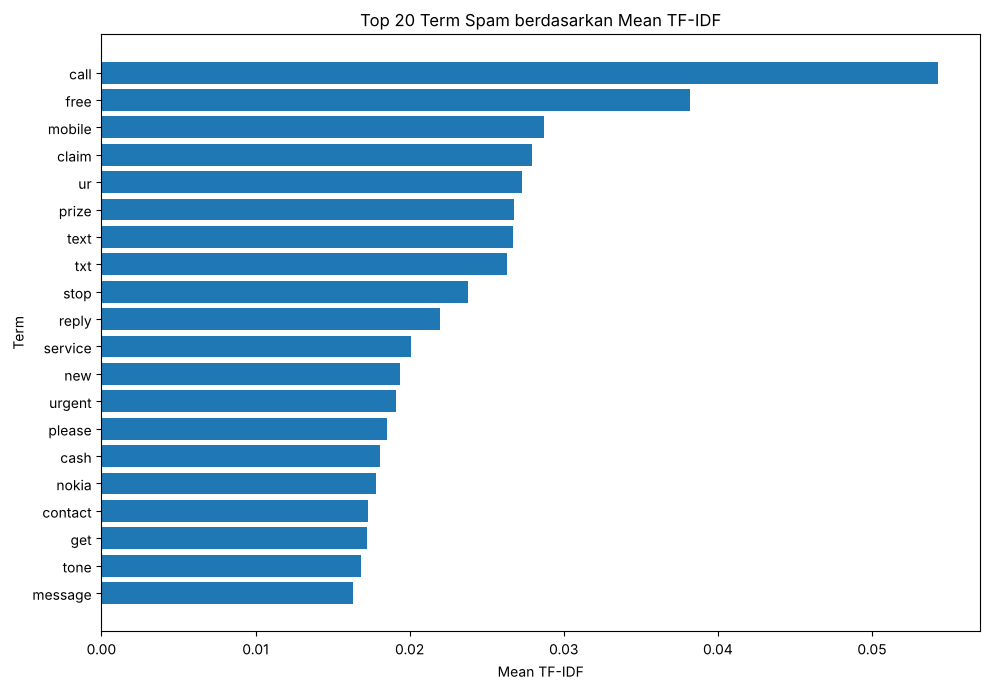

In [9]:
plt.figure(figsize=(10, 7))

plt.barh(
top_20_spam.index[::-1],
top_20_spam["mean_tfidf"][::-1]
)

plt.xlabel("Mean TF-IDF")
plt.ylabel("Term")
plt.title("Top 20 Term Spam berdasarkan Mean TF-IDF")

plt.tight_layout()
plt.show()

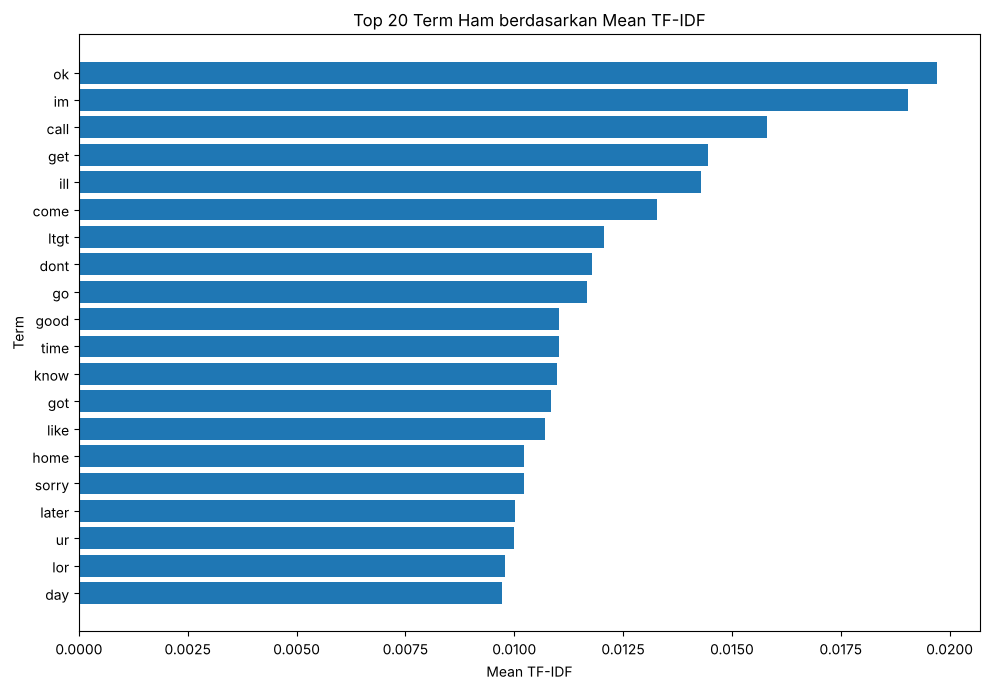

In [10]:
plt.figure(figsize=(10, 7))

plt.barh(
top_20_ham.index[::-1],
top_20_ham["mean_tfidf"][::-1]
)

plt.xlabel("Mean TF-IDF")
plt.ylabel("Term")
plt.title("Top 20 Term Ham berdasarkan Mean TF-IDF")

plt.tight_layout()
plt.show()

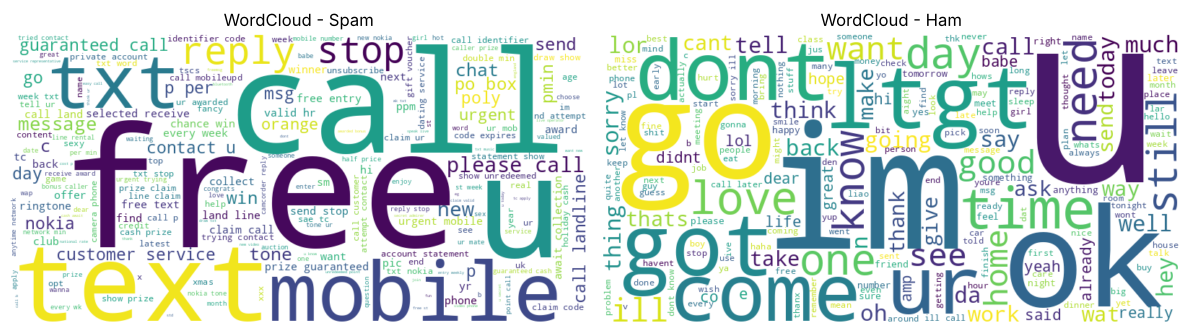

In [11]:
from wordcloud import WordCloud

wordcloud_spam = WordCloud(
width=800,
height=400,
background_color="white"
).generate(df_spam["clean_message"].str.cat(sep=" "))

wordcloud_ham = WordCloud(
width=800,
height=400,
background_color="white"
).generate(df_ham["clean_message"].str.cat(sep=" "))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(wordcloud_spam, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud - Spam")

plt.subplot(1, 2, 2)
plt.imshow(wordcloud_ham, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud - Ham")

plt.tight_layout()
plt.show()